# Chapter 15 — Statistical Modeling with Statsmodels

Statsmodels provides interpretable statistical models with coefficient estimates, uncertainty measures, diagnostics, and formal inference. Learn linear regression, categorical predictors, residual analysis, and time-series foundations.

## Prerequisites
Pandas, NumPy, descriptive statistics, and basic probability; SciPy statistics is recommended.

## Learning goals
- Fit and interpret ordinary least squares regression.
- Use formulas and categorical variables safely.
- Interpret coefficients, confidence intervals, p-values, and model fit.
- Evaluate residual assumptions and recognize model limitations.
- Understand the introductory workflow for time-series analysis.

**Study sequence:** use the theory notebook first, then tutorial, then lab. The examples use the bundled synthetic data unless otherwise noted.

In [1]:
from pathlib import Path
ROOT=Path.cwd()
if not (ROOT/"data").exists() and (ROOT.parent/"data").exists(): ROOT=ROOT.parent
DATA=ROOT/"data"
print("Data directory:", DATA.resolve())

Data directory: /mnt/data/python_data_analysis_book/data


## Guided learning path

Work from top to bottom. Each step states the purpose, explains the API choice, and provides a complete code cell. Modify parameters and predict the output before running it.

### Step 1 — Guided 1 — Define the model question

The response variable is revenue. Predictors are units and discount. Region is categorical; formula syntax adds indicator columns automatically.

In [2]:
from pathlib import Path
ROOT=Path.cwd()
if not (ROOT/"data").exists() and (ROOT.parent/"data").exists(): ROOT=ROOT.parent
DATA=ROOT/"data"
print("Data directory:", DATA.resolve())
import pandas as pd, statsmodels.formula.api as smf
sales=pd.read_csv(DATA/"sales.csv"); print(sales[["revenue","units","discount","region"]].head())

Data directory: /mnt/data/python_data_analysis_book/data
     revenue  units  discount region
0  219935.79     16      0.05  North
1   11895.39     13      0.03   West
2   16659.20      8      0.00   West
3   15634.04      8      0.05  South
4    8934.03      3      0.15   East


### Step 2 — Guided 2 — Fit and read the coefficient table

Fit OLS with a formula. The intercept and category coefficients depend on the reference category and coding. Interpret units in the variable units, not as standardized effects.

In [3]:
model=smf.ols("revenue ~ units + discount + C(region)",data=sales).fit(); print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                revenue   R-squared:                       0.177
Model:                            OLS   Adj. R-squared:                  0.159
Method:                 Least Squares   F-statistic:                     10.04
Date:                Wed, 04 Nov 2026   Prob (F-statistic):           1.02e-08
Time:                        18:19:26   Log-Likelihood:                -3331.4
No. Observations:                 240   AIC:                             6675.
Df Residuals:                     234   BIC:                             6696.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept           -1.19e+05   5.31

### Step 3 — Guided 3 — Diagnose residual structure

Residual patterns can reveal nonlinearity, unequal variance, outliers, or omitted structure. No single diagnostic proves a model is correct.

/mnt/data/python_data_analysis_book/Chapter_15_statistical_modeling_with_statsmodels/Chapter_15_Step_by_Step_Tutorial.ipynb:2: UserWarning:

FigureCanvasAgg is non-interactive, and thus cannot be shown



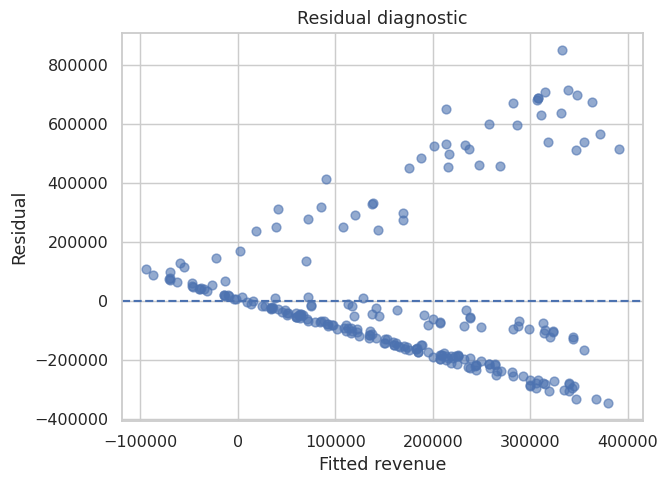

In [4]:
import matplotlib.pyplot as plt
plt.scatter(model.fittedvalues,model.resid,alpha=.6); plt.axhline(0,ls="--"); plt.xlabel("Fitted revenue"); plt.ylabel("Residual"); plt.title("Residual diagnostic"); plt.show()

### Step 4 — Guided 4 — Compare conventional and robust inference

HC3 robust standard errors are often a useful sensitivity analysis under heteroscedasticity. They do not repair non-independent observations or a biased model.

In [5]:
print("Conventional SE"); print(model.bse); print("HC3 robust result"); print(model.get_robustcov_results(cov_type="HC3").summary())

Conventional SE
Intercept              53130.929781
C(region)[T.North]     48833.418180
C(region)[T.South]     47689.764935
C(region)[T.West]      46116.045032
units                   3554.517670
discount              327349.094813
dtype: float64
HC3 robust result
                            OLS Regression Results                            
Dep. Variable:                revenue   R-squared:                       0.177
Model:                            OLS   Adj. R-squared:                  0.159
Method:                 Least Squares   F-statistic:                     7.995
Date:                Wed, 04 Nov 2026   Prob (F-statistic):           5.62e-07
Time:                        18:19:26   Log-Likelihood:                -3331.4
No. Observations:                 240   AIC:                             6675.
Df Residuals:                     234   BIC:                             6696.
Df Model:                           5                                         
Covariance Type:        

## Tutorial checkpoint

1. What was the input data type?
2. What did the function or method return?
3. Which argument most changed the result?
4. What edge case should be tested before using this in production?